# Workshop 3 — Part A (Steps 3 & 4): Feature Engineering & Regression Model Training

## Objective
Explore relationships among harmonized socioeconomic indicators (`gdp`, `family`, `health`, `freedom`, `generosity`, `corruption`), justify feature selection while preventing target leakage, and train/serialize a reproducible `scikit-learn` regression pipeline (`models/model.pkl`) using a 70% / 30% train-test split.

In [1]:
import pickle
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

sns.set_theme(style="whitegrid", palette="deep")

DATA_PATH = Path("../data/processed/happiness_unified.csv") if Path("../data/processed/happiness_unified.csv").exists() else Path("data/processed/happiness_unified.csv")
MODELS_DIR = Path("../models") if Path("../data").exists() else Path("models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)
print(f"Loaded unified dataset: {df.shape[0]} rows x {df.shape[1]} columns")
print(df.describe().T[["count", "mean", "std", "min", "50%", "max"]].round(4))

Loaded unified dataset: 782 rows x 10 columns
                 count       mean     std       min        50%        max
year             782.0  2016.9936  1.4174  2015.000  2017.0000  2019.0000
gdp              782.0     0.9160  0.4073     0.000     0.9822     2.0960
family           782.0     1.0784  0.3295     0.000     1.1247     1.6440
health           782.0     0.6124  0.2483     0.000     0.6473     1.1410
freedom          782.0     0.4111  0.1529     0.000     0.4310     0.7240
generosity       782.0     0.2186  0.1223     0.000     0.2020     0.8381
corruption       782.0     0.1257  0.1060     0.000     0.0910     0.5519
happiness_score  782.0     5.3790  1.1275     2.693     5.3220     7.7690


---
## Step 3 — Feature Engineering & Exploratory Relationships

### 3.1 Correlation Analysis & Feature Relationships
We analyze Pearson correlations and bivariate scatter plots between each candidate predictor and `happiness_score`.

Correlation with target (happiness_score):
happiness_score    1.0000
gdp                0.7893
health             0.7425
family             0.6488
freedom            0.5513
corruption         0.4000
generosity         0.1376
Name: happiness_score, dtype: float64


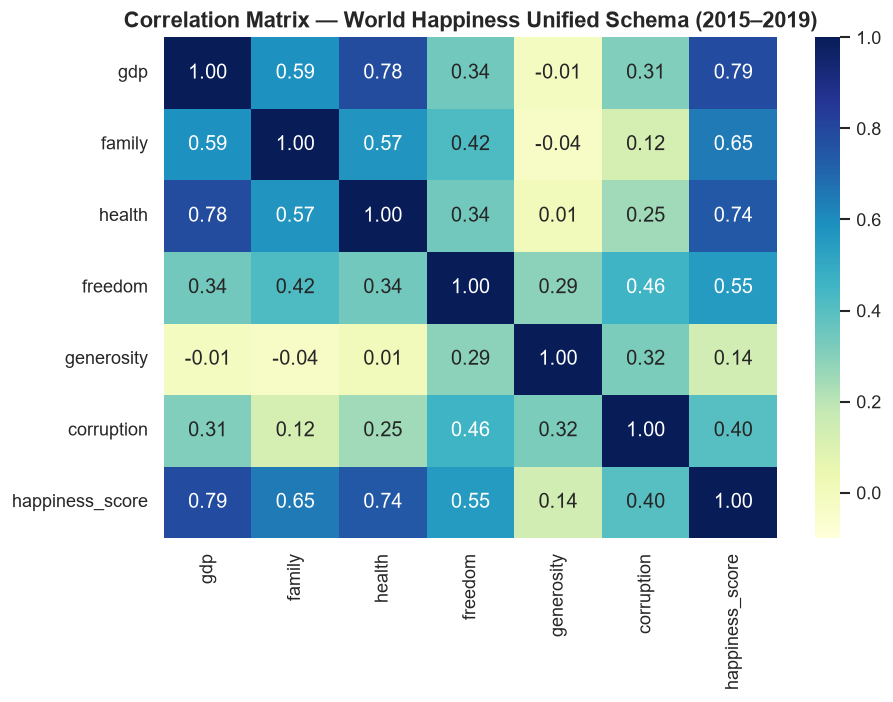

In [2]:
FEATURES = ["gdp", "family", "health", "freedom", "generosity", "corruption"]
TARGET = "happiness_score"

corr_matrix = df[FEATURES + [TARGET]].corr()
print("Correlation with target (happiness_score):")
print(corr_matrix[TARGET].sort_values(ascending=False).round(4))

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="YlGnBu", vmin=-0.1, vmax=1.0, ax=ax)
ax.set_title("Correlation Matrix — World Happiness Unified Schema (2015–2019)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

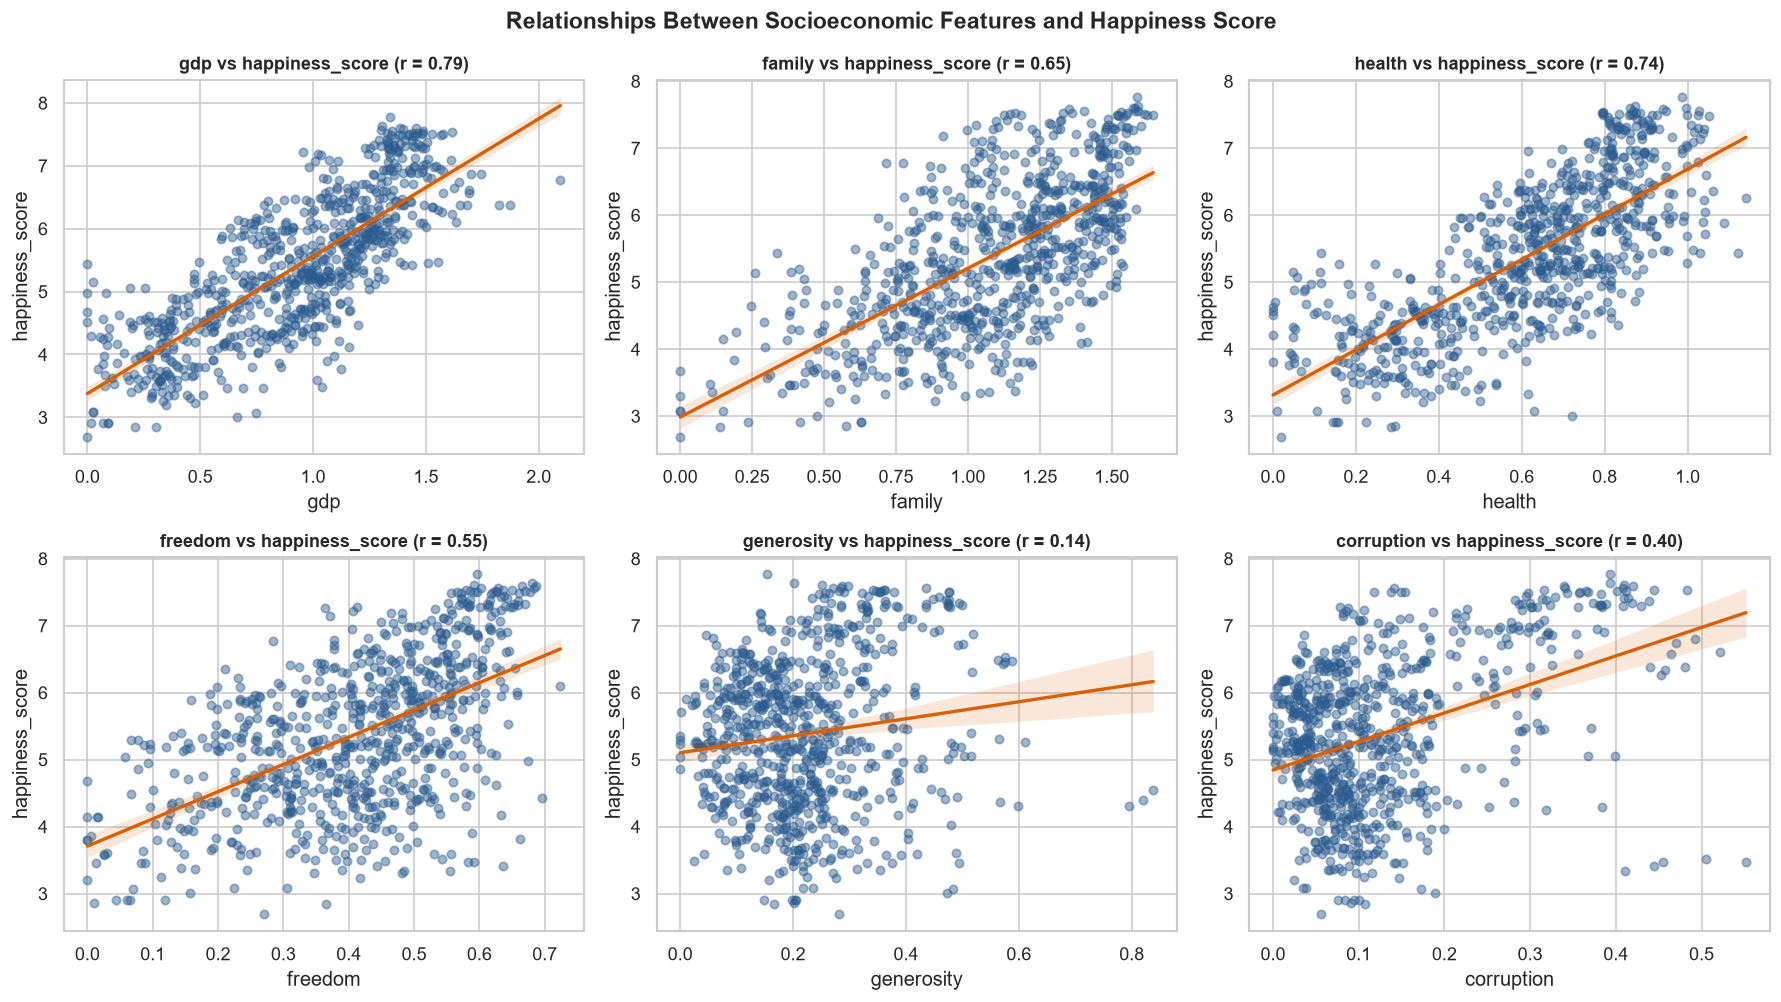

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
axes = axes.flatten()
for idx, feat in enumerate(FEATURES):
    sns.regplot(
        data=df, x=feat, y=TARGET, ax=axes[idx],
        scatter_kws={"alpha": 0.45, "s": 25, "color": "#2b5c8f"},
        line_kws={"color": "#d95f02", "linewidth": 2}
    )
    r_val = df[feat].corr(df[TARGET])
    axes[idx].set_title(f"{feat} vs {TARGET} (r = {r_val:.2f})", fontsize=11, fontweight="bold")
plt.suptitle("Relationships Between Socioeconomic Features and Happiness Score", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### 3.2 Feature Selection, Target Leakage Prevention & Preprocessing Justification

1. **Selected Model Features (`['gdp', 'family', 'health', 'freedom', 'generosity', 'corruption']`)**:
   - **Strong Linear & Non-Linear Drivers**: `gdp` ($r = 0.79$), `health` ($r = 0.74$), `family` ($r = 0.65$), `freedom` ($r = 0.55$), and `corruption` ($r = 0.40$) show strong positive associations with `happiness_score`.
   - **Completeness with Event Contract**: `generosity` ($r = 0.14$) captures prosocial behavior independent of GDP and completes the 6-feature vector specified in the **Part B Kafka Event Contract** (`gdp`, `family`, `health`, `freedom`, `generosity`, `corruption`).
2. **Preventing Target Leakage**:
   - `actual_happiness_score` / `happiness_score` is strictly separated as the target `y` during training and used **only for evaluation (`prediction_error`)** in the Kafka consumer.
   - `Dystopia Residual`, `Happiness Rank`, and confidence intervals were removed during Step 2 because they mathematically encode the target score.
3. **Why `country` and `year` Are Excluded from the Feature Matrix**:
   - `country` serves as the Kafka event partition key and `dim_country` foreign key; one-hot encoding 164 countries would cause high dimensionality and fail if a new country arrives in the stream.
   - `year` serves as temporal metadata (`dim_date`); excluding it ensures the regression model predicts happiness purely from socioeconomic indicators rather than memorizing temporal offsets.
4. **Learned Preprocessing Inside `scikit-learn` `Pipeline`**:
   - `SimpleImputer(strategy="median")`: Safeguards against unexpected `NaN` values if any upstream transformation produces one.
   - `StandardScaler()`: Normalizes all 6 numeric features to zero mean and unit variance (`z-score`), fitted **exclusively on the 70% training split** and serialized inside `model.pkl` to guarantee identical transformations during real-time Kafka consumer inference.

---
## Step 4 — Train, Evaluate & Serialize Regression Model (`model.pkl`)

We split the dataset into **70% training (`547` records)** and **30% testing (`235` records)** (`random_state=42`) and compare the three suggested regression models:
1. `LinearRegression`
2. `DecisionTreeRegressor(max_depth=5, random_state=42)`
3. `RandomForestRegressor(n_estimators=200, random_state=42)`

In [4]:
X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)

# Persist the exact 70/30 split flag into happiness_unified.csv for streaming KPI evaluation
df["is_test_set"] = df.index.isin(X_test.index)
df.to_csv(DATA_PATH, index=False)

print(f"Training set: {X_train.shape[0]} samples (70.0%)")
print(f"Testing set : {X_test.shape[0]} samples (30.0%) — persisted 'is_test_set' in {DATA_PATH.name}\n")

candidate_models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree Regressor": DecisionTreeRegressor(max_depth=5, random_state=42),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=200, random_state=42),
}

eval_rows = []
trained_pipelines = {}
predictions_map = {}

for model_name, estimator in candidate_models.items():
    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("regressor", estimator),
    ])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = root_mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    eval_rows.append({
        "Model": model_name,
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
        "R2": round(r2, 4)
    })
    trained_pipelines[model_name] = pipeline
    predictions_map[model_name] = y_pred

metrics_df = pd.DataFrame(eval_rows).sort_values(by="RMSE", ascending=True)
print("Model Evaluation Results (30% Test Set):")
print(metrics_df.to_string(index=False))

Training set: 547 samples (70.0%)
Testing set : 235 samples (30.0%) — persisted 'is_test_set' in happiness_unified.csv

Model Evaluation Results (30% Test Set):
                  Model    MAE   RMSE     R2
Random Forest Regressor 0.4071 0.5213 0.7823
      Linear Regression 0.4487 0.5846 0.7263
Decision Tree Regressor 0.5205 0.6703 0.6401


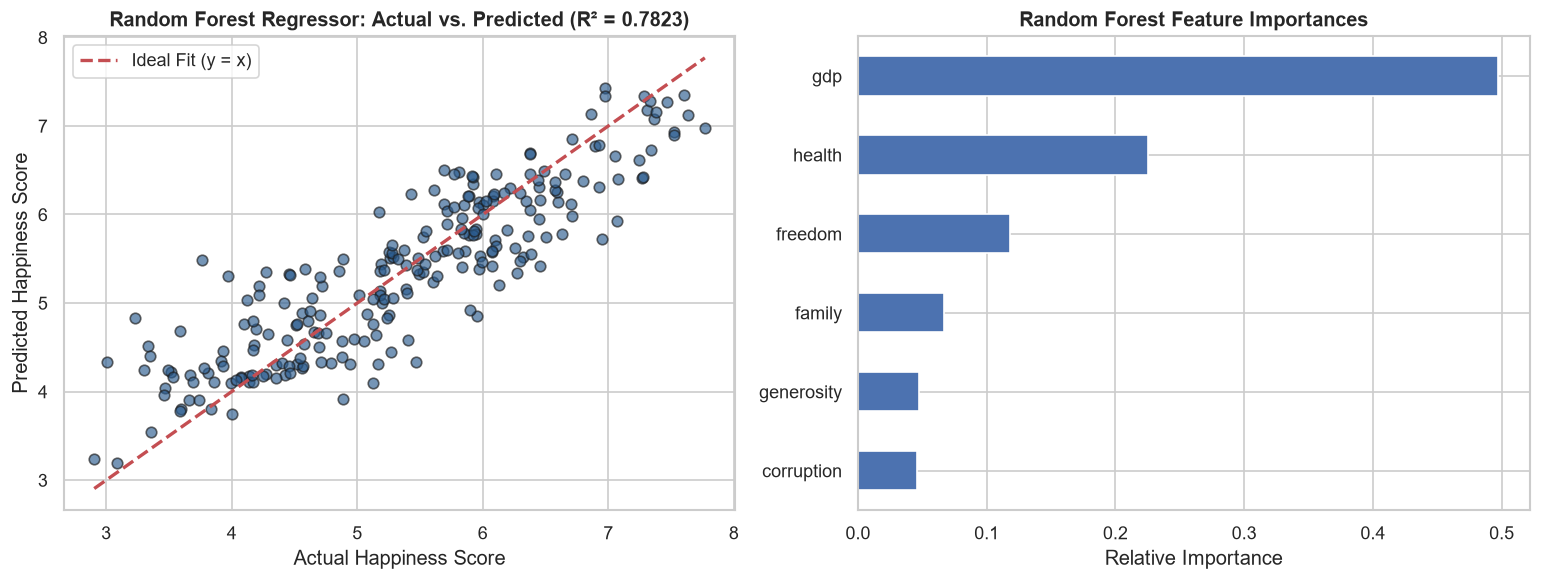

In [5]:
best_model_name = "Random Forest Regressor"
best_pipeline = trained_pipelines[best_model_name]
best_preds = predictions_map[best_model_name]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Actual vs Predicted
axes[0].scatter(y_test, best_preds, alpha=0.65, color="#2b5c8f", edgecolor="k", s=40)
min_v, max_v = min(y_test.min(), best_preds.min()), max(y_test.max(), best_preds.max())
axes[0].plot([min_v, max_v], [min_v, max_v], "r--", lw=2, label="Ideal Fit (y = x)")
axes[0].set_xlabel("Actual Happiness Score")
axes[0].set_ylabel("Predicted Happiness Score")
axes[0].set_title(f"{best_model_name}: Actual vs. Predicted (R² = {r2_score(y_test, best_preds):.4f})", fontweight="bold")
axes[0].legend()

# Plot 2: Feature Importances
rf_importances = best_pipeline.named_steps["regressor"].feature_importances_
imp_series = pd.Series(rf_importances, index=FEATURES).sort_values(ascending=True)
imp_series.plot(kind="barh", ax=axes[1], color="#4C72B0")
axes[1].set_xlabel("Relative Importance")
axes[1].set_title("Random Forest Feature Importances", fontweight="bold")

plt.tight_layout()
plt.show()

### 4.1 Serialize Pipeline (`models/model.pkl`) & Verify Streaming Inference Compatibility
We serialize the full `scikit-learn` `Pipeline` (`imputer` + `scaler` + `regressor`) together with metadata expectations, and verify that a single Kafka JSON payload can be transformed and scored seamlessly.

In [6]:
model_path = MODELS_DIR / "model.pkl"
with open(model_path, "wb") as f:
    pickle.dump(best_pipeline, f)

print(f"Serialized full preprocessing + regression pipeline to: {model_path}")

# Verify loading and single-event inference matching Part B Kafka Event format
with open(model_path, "rb") as f:
    loaded_pipeline = pickle.load(f)

sample_kafka_event = {
    "event_id": "E001",
    "country": "Colombia",
    "year": 2019,
    "gdp": 0.985,
    "family": 1.410,
    "health": 0.841,
    "freedom": 0.470,
    "generosity": 0.099,
    "corruption": 0.034,
    "actual_happiness_score": 6.125,
    "event_time": "2026-10-30T15:30:00"
}

event_features_df = pd.DataFrame([sample_kafka_event])[FEATURES]
predicted_score = float(loaded_pipeline.predict(event_features_df)[0])
pred_error = abs(sample_kafka_event["actual_happiness_score"] - predicted_score)

print("\n--- Real-Time Inference Smoke Test ---")
print(f"Country          : {sample_kafka_event['country']} ({sample_kafka_event['year']})")
print(f"Actual Score     : {sample_kafka_event['actual_happiness_score']:.4f}")
print(f"Predicted Score  : {predicted_score:.4f}")
print(f"Prediction Error : {pred_error:.4f}")

Serialized full preprocessing + regression pipeline to: models\model.pkl

--- Real-Time Inference Smoke Test ---
Country          : Colombia (2019)
Actual Score     : 6.1250
Predicted Score  : 5.9280
Prediction Error : 0.1970
